# 03b · Hyperparameter tuning (XGBoost)

**Goal:** see how much precision we can gain **at a fixed recall of 80%** by tuning XGBoost and adding features.

**Metric optimized:** *precision at 80% recall*. It answers the business question directly:
"if we want to catch 80% of the churners, what share of the customers we call are really at risk?"

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # lets the notebook import src/

import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

sns.set_theme(style="whitegrid")
ACCENT = "#941B50"
pd.set_option("display.max_columns", 50)

In [2]:
from scipy.stats import loguniform, randint, uniform
from sklearn.metrics import make_scorer, precision_recall_curve, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src.train import load_xy, make_preprocessor, split

X, y = load_xy()
X_train, X_test, y_train, y_test = split(X, y)
TARGET_RECALL = 0.80


def precision_at_recall(y_true, y_score, target=TARGET_RECALL):
    """Best precision reachable while keeping recall >= target."""
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    return precision[recall >= target].max()


p_at_r = make_scorer(precision_at_recall, response_method="predict_proba")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)
scoring = {"auc": "roc_auc", "p_at_r80": p_at_r}

## 1. Baseline: the current XGBoost settings

In [3]:
def xgb_pipeline(X_ref, **params):
    base = dict(n_estimators=400, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, min_child_weight=3)
    base.update(params)
    return Pipeline([("prep", make_preprocessor(X_ref)),
                     ("model", XGBClassifier(**base, eval_metric="auc", random_state=config.RANDOM_STATE))])

baseline = cross_validate(xgb_pipeline(X), X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
print(f"Baseline  ROC-AUC = {baseline['test_auc'].mean():.3f} | precision @ 80% recall = {baseline['test_p_at_r80'].mean():.3f}")

Baseline  ROC-AUC = 0.845 | precision @ 80% recall = 0.520


## 2. Randomized search

We try 60 random combinations, each evaluated with 5-fold cross-validation (300 fits, a few minutes).

| Parameter | What it controls |
|---|---|
| `n_estimators` | number of trees |
| `learning_rate` | how much each tree corrects the previous ones (small = slower but more careful) |
| `max_depth` | depth of each tree (deeper = more complex interactions, more overfitting risk) |
| `min_child_weight` | minimum data in a leaf (higher = more conservative) |
| `subsample`, `colsample_bytree` | share of rows / columns used per tree (adds randomness, reduces overfitting) |
| `gamma` | minimum gain required to split (higher = simpler trees) |
| `reg_alpha`, `reg_lambda` | L1 / L2 regularization of the leaf weights |

In [4]:
search_space = {
    "model__n_estimators": randint(200, 1200),
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__max_depth": randint(2, 7),
    "model__min_child_weight": randint(1, 12),
    "model__subsample": uniform(0.6, 0.4),
    "model__colsample_bytree": uniform(0.4, 0.6),
    "model__gamma": uniform(0, 5),
    "model__reg_alpha": loguniform(1e-3, 5),
    "model__reg_lambda": loguniform(0.1, 20),
}

search = RandomizedSearchCV(
    xgb_pipeline(X), search_space, n_iter=60, scoring=scoring, refit="p_at_r80",
    cv=cv, n_jobs=-1, random_state=config.RANDOM_STATE, verbose=1,
)
search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_)
best = results.loc[search.best_index_]
print(f"Tuned     ROC-AUC = {best['mean_test_auc']:.3f} | precision @ 80% recall = {best['mean_test_p_at_r80']:.3f}")
best_params = {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()}
best_params

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Tuned     ROC-AUC = 0.850 | precision @ 80% recall = 0.531


{'colsample_bytree': 0.7136396976291964,
 'gamma': 2.137705091792748,
 'learning_rate': 0.010791232418686401,
 'max_depth': 6,
 'min_child_weight': 3,
 'n_estimators': 774,
 'reg_alpha': 2.0577976710806443,
 'reg_lambda': 1.2411982157011463,
 'subsample': 0.8253102287905535}

In [5]:
top = results.sort_values("mean_test_p_at_r80", ascending=False).head(10)
top[["mean_test_p_at_r80", "std_test_p_at_r80", "mean_test_auc"] + [c for c in results.columns if c.startswith("param_")]].round(3)

,mean_test_p_at_r80,std_test_p_at_r80,mean_test_auc,param_model__colsample_bytree,param_model__gamma,param_model__learning_rate,param_model__max_depth,param_model__min_child_weight,param_model__n_estimators,param_model__reg_alpha,param_model__reg_lambda,param_model__subsample
12,0.531,0.020,0.850,0.714,2.138,0.011,6,3,774,2.058,1.241,0.825
46,0.530,0.023,0.851,0.591,4.224,0.011,3,3,816,0.068,3.930,0.739
52,0.530,0.025,0.850,0.434,3.685,0.051,4,2,950,0.003,5.653,0.847
30,0.530,0.024,0.850,0.972,4.574,0.030,2,5,479,0.017,1.870,0.829
10,0.530,0.023,0.850,0.949,4.250,0.038,2,7,606,0.298,3.406,0.837
35,0.530,0.020,0.848,0.803,1.641,0.016,6,6,513,1.523,0.377,0.616
9,0.529,0.025,0.850,0.403,4.077,0.083,4,3,488,0.174,13.535,0.860
23,0.529,0.021,0.849,0.796,4.086,0.053,5,1,201,4.843,16.652,0.823
56,0.529,0.020,0.849,0.643,2.857,0.092,6,9,1134,0.575,2.200,0.985
15,0.529,0.028,0.851,0.614,4.534,0.023,4,9,827,0.020,0.503,0.666


Look at `std_test_p_at_r80`: if the gap between the best combinations is smaller than this standard deviation,
the "winner" is partly luck. That is normal and worth saying in an interview.

## 3. Do the extra features from notebook 02 help?

In [6]:
def add_extra(df):
    df = df.copy()
    df["AutoPayment"] = df["PaymentMethod"].str.contains("automatic").astype(int)
    protect = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
    df["NumProtection"] = (df[protect] == "Yes").sum(axis=1)
    df["AvgChargePerMonth"] = df["TotalCharges"] / df["tenure"].replace(0, 1)
    return df

X_train_extra = add_extra(X_train)
extra = cross_validate(xgb_pipeline(X_train_extra, **best_params), X_train_extra, y_train, cv=cv, scoring=scoring, n_jobs=-1)
print(f"Tuned + extra features  ROC-AUC = {extra['test_auc'].mean():.3f} | precision @ 80% recall = {extra['test_p_at_r80'].mean():.3f}")

Tuned + extra features  ROC-AUC = 0.849 | precision @ 80% recall = 0.522


If the extra features give a clear gain (more than ~0.01), add them to `add_features()` in `src/preprocess.py`,
re-run `python -m src.preprocess`, then re-run this notebook. Otherwise keep the model simpler.

## 4. Final check on the test set (never used during tuning)

In [7]:
tuned = xgb_pipeline(X, **best_params).fit(X_train, y_train)
base = xgb_pipeline(X).fit(X_train, y_train)

rows = []
for name, model in {"Baseline": base, "Tuned": tuned}.items():
    p = model.predict_proba(X_test)[:, 1]
    rows.append({"model": name, "roc_auc": roc_auc_score(y_test, p),
                 "precision_at_80_recall": precision_at_recall(y_test, p),
                 "expected_churners": p.sum(), "actual_churners": int(y_test.sum())})
summary = pd.DataFrame(rows).set_index("model").round(3)
summary

,roc_auc,precision_at_80_recall,expected_churners,actual_churners
model,,,,
Baseline,0.844,0.515,374.209991,374
Tuned,0.848,0.522,375.592987,374


Threshold for recall >= 80%: 0.25


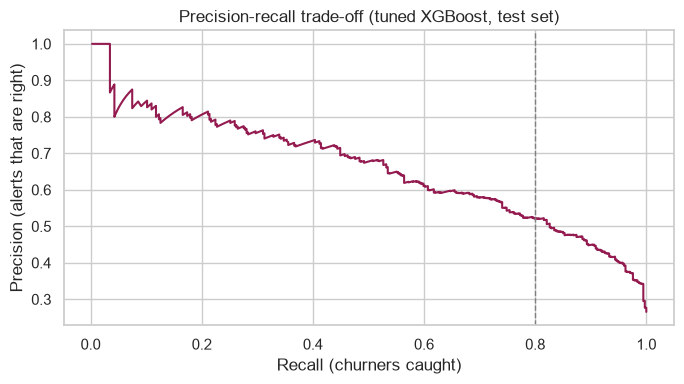

In [8]:
proba = tuned.predict_proba(X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, proba)
table = pd.DataFrame({"threshold": thresholds, "precision": precision[:-1], "recall": recall[:-1]})

# Threshold giving the best precision while keeping recall >= 80%
ok = table[table["recall"] >= TARGET_RECALL]
THRESHOLD = round(float(ok.loc[ok["precision"].idxmax(), "threshold"]), 2)
print(f"Threshold for recall >= {TARGET_RECALL:.0%}: {THRESHOLD}")

plt.figure(figsize=(7, 4))
plt.plot(table["recall"], table["precision"], color=ACCENT)
plt.axvline(TARGET_RECALL, color="grey", linestyle="--", linewidth=1)
plt.xlabel("Recall (churners caught)"); plt.ylabel("Precision (alerts that are right)")
plt.title("Precision-recall trade-off (tuned XGBoost, test set)")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "03b_precision_recall.png", dpi=150); plt.show()

## 5. Save and retrain

Only save the tuned parameters if they really beat the baseline **on the test set** (section 4).
Then `src/train.py` uses them automatically. Also copy the new threshold into `THRESHOLD` in `src/train.py`.

In [9]:
if summary.loc["Tuned", "precision_at_80_recall"] > summary.loc["Baseline", "precision_at_80_recall"]:
    config.BEST_PARAMS_PATH.parent.mkdir(parents=True, exist_ok=True)
    config.BEST_PARAMS_PATH.write_text(json.dumps(best_params, indent=2))
    print(f"Tuned parameters saved to {config.BEST_PARAMS_PATH}")

    from src import train
    train.main(threshold=THRESHOLD)
else:
    print("No gain on the test set: keep the default parameters (nothing saved).")

Tuned parameters saved to C:\Users\USER\Desktop\churn-retention-dashboard\models\xgb_best_params.json
ROC-AUC: 0.848 | Recall (churners) @ 0.25: 0.816
[[754 281]
 [ 69 305]]
              precision    recall  f1-score   support

        Stay       0.92      0.73      0.81      1035
       Churn       0.52      0.82      0.64       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

Model saved to C:\Users\USER\Desktop\churn-retention-dashboard\models\churn_model.joblib
